## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**
Una plataforma de red social quiere analizar las conexiones de amistad entre sus usuarios. Cada usuario es un vértice y cada amistad es una arista.

El sistema debe permitir:

Explorar la red desde un usuario, en anchura (BFS) y en profundidad (DFS).
Usar BFS para encontrar la conexión con la menor cantidad de saltos entre dos usuarios (grados de separación).
Agregar un usuario nuevo conectado con usuarios que ya existen.

Red inicial

Usuarios: Ana, Carlos, Laura, Mateo, Sofía, Daniel, Valentina.
Amistades: Ana-Carlos, Ana-Laura, Carlos-Mateo, Carlos-Sofía, Laura-Daniel, Sofía-Valentina, Daniel-Valentina.

El grafo es **no dirigido**: si Ana es amiga de Carlos, Carlos también es amigo de Ana.


## 2) Requerimientos **[2 pts]**

REQUERIMIENTOS FUNCIONALES

-RF01: REPRESENTACION LA RED — El sistema debe guardar los usuarios y sus amistades en una lista de adyacencia, y cada amistad debe quedar registrada en ambos sentidos.

-RF02: VISUALIZACION LA RED — El sistema debe mostrar cada usuario junto con las personas conectadas directamente con él.

-RF03: EXPLORACION CON BFS — El sistema debe recorrer la red con BFS desde un usuario, usando una cola, y mostrar el orden de visita y el grado de separación de cada usuario respecto al origen.

-RF04: EXPLORACION CON DFS — El sistema debe recorrer la red con DFS desde un usuario, usando recursividad, y mostrar el orden de visita.

-RF05: ELECCION USUARIO INICIAL Y VALIDACIONN — El sistema debe permitir al usuario escribir desde qué persona inician los recorridos, ejecutar BFS y DFS desde ella, y mostrar un mensaje de error si el nombre no existe.

-RF06: BUSQUEDA DE LA CONEXIÓN ENTRE DOS PERSONAS — El sistema debe pedir un usuario inicial y un usuario destino, encontrar con BFS una ruta con la menor cantidad de conexiones, mostrarla junto con los grados de separación, e indicar claramente si no existe conexión.

-RF07: AGREGAR USUARIO — El sistema debe permitir registrar un usuario nuevo conectado con al menos dos usuarios existentes, mostrar la red actualizada y permitir ejecutar de nuevo BFS, DFS y la búsqueda de una ruta.

-RF08: NO VALIDACION DUPLICADOS — El sistema no debe registrar dos veces la misma amistad.

REQUERIMIENTOS NO FUNCIONALES

-RNF01: EFICIENCIA — BFS, DFS y la búsqueda de ruta deben ejecutarse en tiempo O(V + E), donde V es el número de usuarios y E el número de amistades.

-RNF02: VISITAS ÚNICAS — Cada usuario debe visitarse una sola vez en cada recorrido, para lo cual se mantiene una estructura de usuarios visitados.

-RNF03: SIN LIBRERÍAS DE RECORRIDO— BFS y DFS deben implementarse a mano, sin librerías que los implementen directamente.

-RNF04: LEGIBILIDAD — Los errores y resultados deben mostrarse con mensajes claros.

-RNF05: MANTENIBILIDAD — El código debe estar dividido en funciones pequeñas, para que sea fácil de entender y modificar.

-RNF06: LENGUAJE —  Se programa en Python porque el lenguaje Python es un lenguaje facil de comprender el cual permite mayor aprendizaje y entendimiento.



## 3) Historias de usuario **[2 pts]**

-HU01: CONSULTA DE LA RED: Como usuario quiero ver cada persona con los amigos con los que está conectada directamente, para conocer cómo está armada la red.

Criterios de aceptación:
 - El sistema muestra todos los usuarios, cada uno con la lista de sus amigos.
 -No hay repetidos.


-HU02: EXPLORAR CONTACTOS CON BFS: Como usuario, quiero escribir un usuario inicial y explorar la red con BFS, para ver el orden de visita y el grado de separación de cada persona.

*Criterios de aceptación:*
 - Si el nombre no existe, el sistema muestra un mensaje de error y no ejecuta el recorrido.
 - El usuario inicial tiene grado 0 y sus amigos directos tienen grado 1.
 - No hay repetidos.
 - El sistema muestra el orden de visita y los usuarios de cada grado.


-HU03: EXPLORAR LA RED CON DFS:Como usuario, quiero explorar la red con DFS desde un usuario, para ver hasta dónde llega una rama de amistades antes de regresar.

Criterios de aceptación:
 - Si el nombre no existe, el sistema muestra un mensaje de error.
 - El recorrido avanza por una rama hasta donde sea posible antes de regresar.
 - No hay repetidos.


-HU04: CONEXIÓN MÁS CORTA: Como usuario, quiero indicar dos personas, para conocer la ruta con la menor cantidad de conexiones entre ellas.

Criterios de aceptación:
 - Si alguno de los dos usuarios no existe, el sistema muestra un mensaje de error.
 - Si hay conexión, el sistema muestra la ruta y los grados de separación.
 - Si no hay conexión, el sistema lo indica claramente.
 - Si el origen y el destino son el mismo usuario, la ruta tiene un solo usuario y 0 grados.


-HU05: NUEVO USUARIO: Como administrador, quiero registrar un usuario nuevo conectado con usuarios existentes, para mantener la red actualizada.

Criterios de aceptación:
 - El sistema no permite registrar un usuario que ya existe.
 - El usuario nuevo debe conectarse con al menos dos usuarios existentes; los  nombres que no existen se ignoran con un aviso.
 - Las amistades nuevas se guardan en ambos sentidos.
 - Después de agregarlo, el sistema muestra la red actualizada y permite ejecutar de nuevo BFS, DFS y la búsqueda de ruta.

## 4) Diagramas de flujo **[5 pts]**
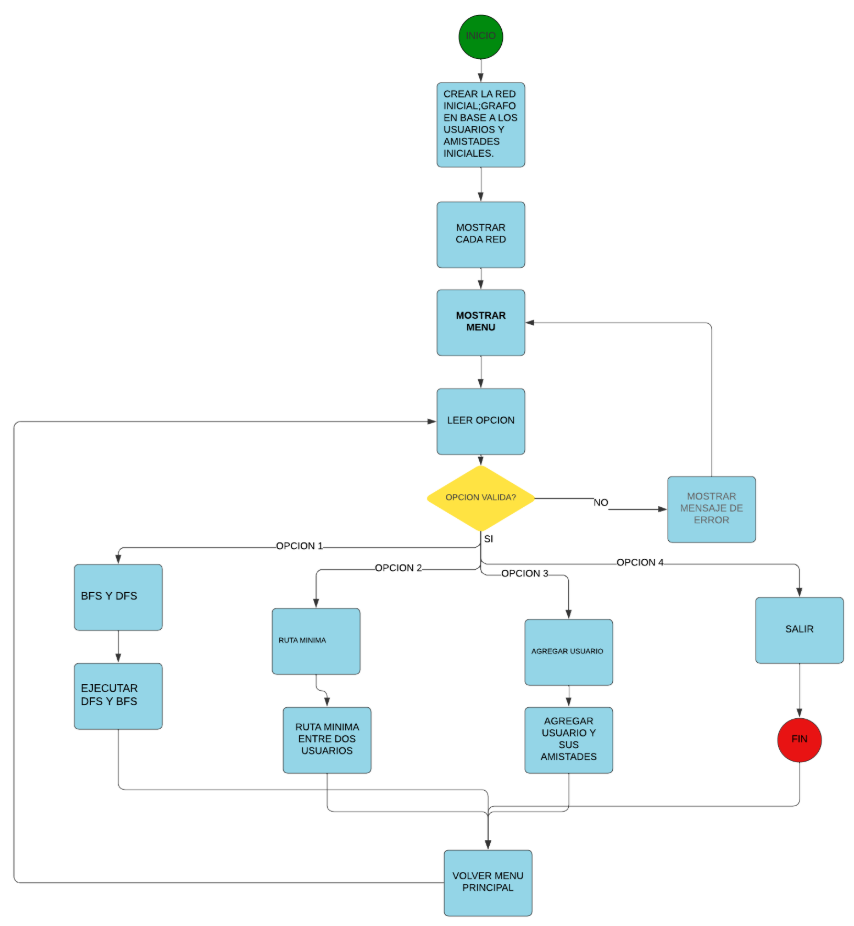

### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
la grafica T(n) representa el crecimiento del numero de operaciones de el sistema de forma que crece el numero de usuarios, si su comportamiento es lineal cuando el numero de amigos es proporcional al numero de usuarios, por lo que decimos que su complejidad es de O(V+E)
mejor caso: se ve como una línea recta en horizontal, donde nos dice un tiempo es constante (O(1)), esto ocurre cuando el usuario de el inicio no tiene amigos por lo que el sistema termina rápidamente
peor caso: se ve como una recta creciente porque el sistema debe recorrer todos los usuarios y conexiones a cada uno, su complejidad es (O(V+E)) ya que el coste aumenta con el tamaño de la red
- Función T[n]
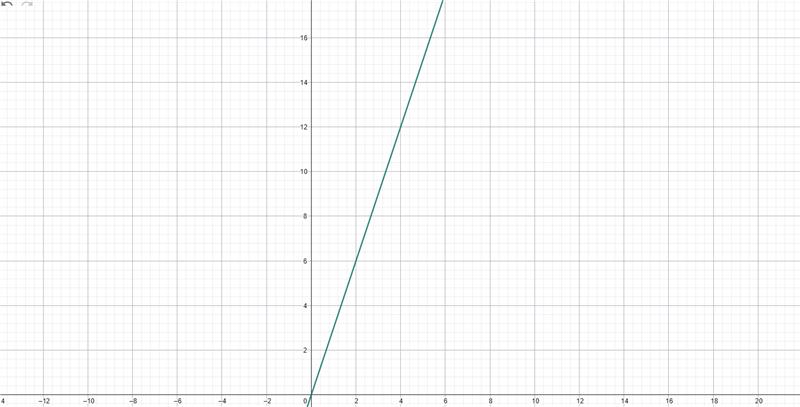
- Mejor y peor caso con gráfica
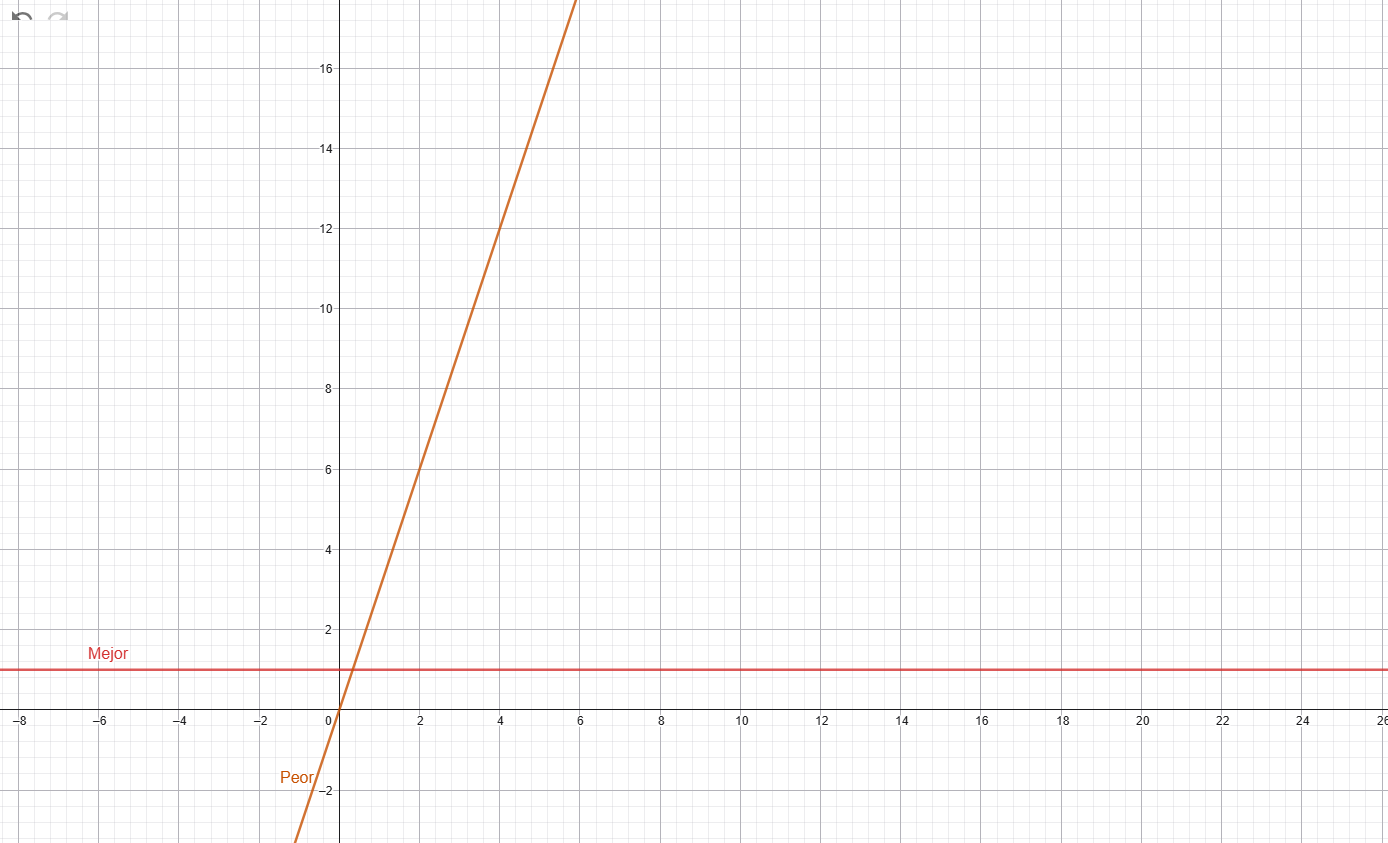

## 6) Código funcional **[15 pts]**


### Punto 1. Representar la red social

In [ ]:
from collections import deque


red = {}

def agregar_usuario(red, nombre):

    if nombre not in red:
        red[nombre] = []

def agregar_amistad(red, a, b):

    if a in red and b in red and a != b:
        if b not in red[a]:
            red[a].append(b)
            red[b].append(a)

def mostrar_red(red):
    for usuario in red:
        print(usuario + ": " + ", ".join(red[usuario]))


for nombre in ["Ana", "Carlos", "Laura", "Mateo", "Sofía", "Daniel", "Valentina"]:
    agregar_usuario(red, nombre)


agregar_amistad(red, "Ana", "Carlos")
agregar_amistad(red, "Ana", "Laura")
agregar_amistad(red, "Carlos", "Mateo")
agregar_amistad(red, "Carlos", "Sofía")
agregar_amistad(red, "Laura", "Daniel")
agregar_amistad(red, "Sofía", "Valentina")
agregar_amistad(red, "Daniel", "Valentina")

mostrar_red(red)

Ana: Carlos, Laura
Carlos: Ana, Mateo, Sofía
Laura: Ana, Daniel
Mateo: Carlos
Sofía: Carlos, Valentina
Daniel: Laura, Valentina
Valentina: Sofía, Daniel


### Punto 2. Explorar contactos con BFS (con cola)



In [ ]:
def bfs(red, inicio):
    visitados = {inicio}
    cola = deque([inicio])
    grados = {inicio: 0}
    orden = []

    while len(cola) > 0:
        actual = cola.popleft()
        orden.append(actual)
        for amigo in red[actual]:
            if amigo not in visitados:
                visitados.add(amigo)
                cola.append(amigo)
                grados[amigo] = grados[actual] + 1

    return orden, grados

def mostrar_bfs(red, inicio):
    orden, grados = bfs(red, inicio)
    print("Recorrido BFS desde " + inicio + ":")
    print(" -> ".join(orden))
    grado_maximo = max(grados.values())
    for grado in range(grado_maximo + 1):
        usuarios_del_grado = []
        for usuario in orden:
            if grados[usuario] == grado:
                usuarios_del_grado.append(usuario)
        print("Grado " + str(grado) + ": " + ", ".join(usuarios_del_grado))

mostrar_bfs(red, "Ana")

Recorrido BFS desde Ana:
Ana -> Carlos -> Laura -> Mateo -> Sofía -> Daniel -> Valentina
Grado 0: Ana
Grado 1: Carlos, Laura
Grado 2: Mateo, Sofía, Daniel
Grado 3: Valentina


### Punto 3. Explorar la red con DFS (recursivo)



In [ ]:
def dfs(red, usuario, visitados, orden):
    visitados.add(usuario)
    orden.append(usuario)
    for amigo in red[usuario]:
        if amigo not in visitados:
            dfs(red, amigo, visitados, orden)

def mostrar_dfs(red, inicio):
    orden = []
    dfs(red, inicio, set(), orden)
    print("Recorrido DFS desde " + inicio + ":")
    print(" -> ".join(orden))

mostrar_dfs(red, "Ana")

Recorrido DFS desde Ana:
Ana -> Carlos -> Mateo -> Sofía -> Valentina -> Daniel -> Laura


### Punto 4. Seleccionar cualquier usuario inicial



In [ ]:
def ejecutar_recorridos(red):
    inicio = input("Ingrese el usuario inicial: ").strip()
    if inicio not in red:
        print("Error: el usuario '" + inicio + "' no existe en la red.")
    else:
        mostrar_bfs(red, inicio)
        mostrar_dfs(red, inicio)

ejecutar_recorridos(red)

Ingrese el usuario inicial: Ana
Recorrido BFS desde Ana:
Ana -> Carlos -> Laura -> Mateo -> Sofía -> Daniel -> Valentina
Grado 0: Ana
Grado 1: Carlos, Laura
Grado 2: Mateo, Sofía, Daniel
Grado 3: Valentina
Recorrido DFS desde Ana:
Ana -> Carlos -> Mateo -> Sofía -> Valentina -> Daniel -> Laura


### Punto 5. Encontrar la conexión entre dos personas



In [ ]:
def ruta_minima(red, origen, destino):
    visitados = {origen}
    cola = deque([origen])
    padre = {origen: None}

    while len(cola) > 0:
        actual = cola.popleft()
        if actual == destino:

            ruta = []
            while actual is not None:
                ruta.append(actual)
                actual = padre[actual]
            ruta.reverse()
            return ruta
        for amigo in red[actual]:
            if amigo not in visitados:
                visitados.add(amigo)
                padre[amigo] = actual
                cola.append(amigo)

    return None

def buscar_ruta(red):
    origen = input("Usuario inicial: ").strip()
    destino = input("Usuario destino: ").strip()
    if origen not in red or destino not in red:
        print("Error: alguno de los usuarios no existe en la red.")
    else:
        ruta = ruta_minima(red, origen, destino)
        if ruta is None:
            print("No existe una conexión entre " + origen + " y " + destino + ".")
        else:
            print("Ruta encontrada:")
            print(" -> ".join(ruta))
            print("Grados de separación:", len(ruta) - 1)

buscar_ruta(red)

Usuario inicial: Ana
Usuario destino: Mateo
Ruta encontrada:
Ana -> Carlos -> Mateo
Grados de separación: 2


### Punto 6. Agregar un nuevo usuario y sus conexiones


In [ ]:
def agregar_usuario_nuevo(red):
    nuevo = input("Nuevo usuario: ").strip()

    if nuevo in red:
        print("Error: el usuario ya existe.")
        return

    conexiones_nuevas = []
    while True:
        otro = input("Conectar con (Enter para terminar): ").strip()
        if otro == "":
            break
        if otro in red and otro not in conexiones_nuevas:
            conexiones_nuevas.append(otro)
        else:
            print("Aviso: '" + otro + "' no existe o ya lo ingresó.")

    if len(conexiones_nuevas) < 2:
        print("Error: se necesitan al menos dos usuarios existentes.")
    else:
        agregar_usuario(red, nuevo)
        for otro in conexiones_nuevas:
            agregar_amistad(red, nuevo, otro)
        print("Usuario agregado. Red actualizada:")
        mostrar_red(red)

agregar_usuario_nuevo(red)

Nuevo usuario: Mateo
Error: el usuario ya existe.


Con la red actualizada, este menú permite ejecutar de nuevo BFS, DFS y la búsqueda de una ruta.

In [ ]:
while True:
    print()
    print("1. BFS y DFS desde un usuario")
    print("2. Buscar la conexión entre dos usuarios")
    print("3. Agregar un usuario")
    print("4. Salir")
    opcion = input("Elija una opción: ").strip()
    if opcion == "1":
        ejecutar_recorridos(red)
    elif opcion == "2":
        buscar_ruta(red)
    elif opcion == "3":
        agregar_usuario_nuevo(red)
    elif opcion == "4":
        break
    else:
        print("Opción no válida.")


1. BFS y DFS desde un usuario
2. Buscar la conexión entre dos usuarios
3. Agregar un usuario
4. Salir
Elija una opción: 1
Ingrese el usuario inicial: Ana
Recorrido BFS desde Ana:
Ana -> Carlos -> Laura -> Mateo -> Sofía -> Daniel -> Valentina
Grado 0: Ana
Grado 1: Carlos, Laura
Grado 2: Mateo, Sofía, Daniel
Grado 3: Valentina
Recorrido DFS desde Ana:
Ana -> Carlos -> Mateo -> Sofía -> Valentina -> Daniel -> Laura

1. BFS y DFS desde un usuario
2. Buscar la conexión entre dos usuarios
3. Agregar un usuario
4. Salir
Elija una opción: 2
Usuario inicial: Ana
Usuario destino: Mateo
Ruta encontrada:
Ana -> Carlos -> Mateo
Grados de separación: 2

1. BFS y DFS desde un usuario
2. Buscar la conexión entre dos usuarios
3. Agregar un usuario
4. Salir
Elija una opción: 3
Nuevo usuario: Sofia
Conectar con (Enter para terminar): Mateo
Conectar con (Enter para terminar): Laura
Conectar con (Enter para terminar): 
Usuario agregado. Red actualizada:
Ana: Carlos, Laura
Carlos: Ana, Mateo, Sofía
Laura:

## 7) Tests aplicados **[15 pts]**

In [ ]:

red_t = {}
for nombre in ["Ana", "Carlos", "Laura", "Mateo", "Sofía", "Daniel", "Valentina"]:
    agregar_usuario(red_t, nombre)
amistades = [("Ana", "Carlos"), ("Ana", "Laura"), ("Carlos", "Mateo"), ("Carlos", "Sofía"),
             ("Laura", "Daniel"), ("Sofía", "Valentina"), ("Daniel", "Valentina")]
for a, b in amistades:
    agregar_amistad(red_t, a, b)

# Test 1
assert len(red_t) == 7
assert red_t["Ana"] == ["Carlos", "Laura"]
assert red_t["Carlos"] == ["Ana", "Mateo", "Sofía"]
assert red_t["Laura"] == ["Ana", "Daniel"]

# Test 2
for usuario in red_t:
    for amigo in red_t[usuario]:
        assert usuario in red_t[amigo]

# Test 3
agregar_amistad(red_t, "Ana", "Carlos")
agregar_amistad(red_t, "Carlos", "Ana")
assert red_t["Ana"] == ["Carlos", "Laura"]
assert red_t["Carlos"] == ["Ana", "Mateo", "Sofía"]

# Test 4
orden, grados = bfs(red_t, "Ana")
assert orden == ["Ana", "Carlos", "Laura", "Mateo", "Sofía", "Daniel", "Valentina"]
assert grados == {"Ana": 0, "Carlos": 1, "Laura": 1, "Mateo": 2, "Sofía": 2, "Daniel": 2, "Valentina": 3}
assert len(orden) == len(set(orden)) == 7

# Test 5
orden_dfs = []
dfs(red_t, "Ana", set(), orden_dfs)
assert orden_dfs == ["Ana", "Carlos", "Mateo", "Sofía", "Valentina", "Daniel", "Laura"]
assert len(orden_dfs) == len(set(orden_dfs)) == 7

# Test 6
orden_sofia, grados_sofia = bfs(red_t, "Sofía")
assert orden_sofia[0] == "Sofía" and grados_sofia["Sofía"] == 0
assert len(orden_sofia) == 7

# Test 7
assert ruta_minima(red_t, "Ana", "Valentina") == ["Ana", "Carlos", "Sofía", "Valentina"]
assert len(ruta_minima(red_t, "Ana", "Valentina")) - 1 == 3
assert ruta_minima(red_t, "Ana", "Ana") == ["Ana"]

# Test 8
agregar_usuario(red_t, "Juliana")
agregar_amistad(red_t, "Juliana", "Mateo")
agregar_amistad(red_t, "Juliana", "Daniel")
assert red_t["Juliana"] == ["Mateo", "Daniel"]
assert "Juliana" in red_t["Mateo"] and "Juliana" in red_t["Daniel"]
assert ruta_minima(red_t, "Ana", "Juliana") == ["Ana", "Carlos", "Mateo", "Juliana"]
assert len(bfs(red_t, "Ana")[0]) == 8

# Test 9
agregar_usuario(red_t, "Pedro")
assert ruta_minima(red_t, "Ana", "Pedro") is None

print("Todos los tests pasaron")

NameError: name 'agregar_usuario' is not defined